# Week 6: Feature Engineering

## 1. Introduction
In this week's sprint, we transition from Exploratory Data Analysis to **Feature Engineering**. 
Our objectives are:
1. **Fixing Skewness:** Applying transformations (like Cube Root) to highly skewed numerical variables.
2. **Scaling & Normalization:** Using techniques like MinMax Scaling to bring numerical features onto a similar scale (crucial for distance-based ML algorithms like PCA in Week 7).
3. **Encoding Categorical Variables:** Transforming text-based categories (like Airlines or Airports) into numerical formats that algorithms can understand.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder

sns.set_theme(style="whitegrid")

# Load the dataset
df = pd.read_csv('../Week_3/flight_delay_cleaned.csv')
print(f"Original Shape: {df.shape}")
display(df.head())

Original Shape: (1747822, 27)


,YEAR,MONTH,DAY_OF_MONTH,OP_UNIQUE_CARRIER,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,ORIGIN,ORIGIN_CITY_NAME,DEST_AIRPORT_ID,...,ARR_TIME,ARR_DELAY,CANCELLED,DIVERTED,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,DelayCategory
0,2024,1,1,9E,10135,1013506,30135,ABE,"Allentown/Bethlehem/Easton, PA",10397,...,757.0,-35.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,On-Time/Early
1,2024,1,1,9E,10135,1013506,30135,ABE,"Allentown/Bethlehem/Easton, PA",10397,...,1437.0,-13.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,On-Time/Early
2,2024,1,1,9E,10185,1018502,30185,AEX,"Alexandria, LA",10397,...,821.0,-29.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,On-Time/Early
3,2024,1,1,9E,10185,1018502,30185,AEX,"Alexandria, LA",10397,...,1851.0,-26.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,On-Time/Early
4,2024,1,1,9E,10208,1020803,30208,AGS,"Augusta, GA",10397,...,1947.0,-23.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,On-Time/Early


## Checking for skewness

(-50.0, 300.0)

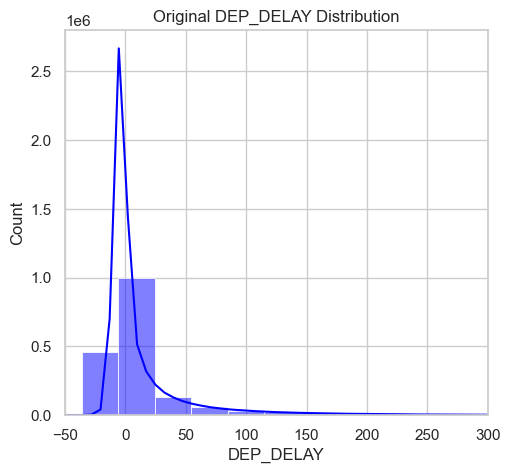

In [14]:
# Analyzing Skewness of DEP_DELAY
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['DEP_DELAY'], kde=True, color='blue', bins=50)
plt.title('Original DEP_DELAY Distribution')
plt.xlim(-50, 300) # Zooming in

## 2. Fixing Skewness
Variables like `DEP_DELAY` often have a right-skewed distribution (many short delays, a few very long ones). We apply a **Cube Root Transformation** to normalize the distribution shape since it can handle negative numbers gracefully.

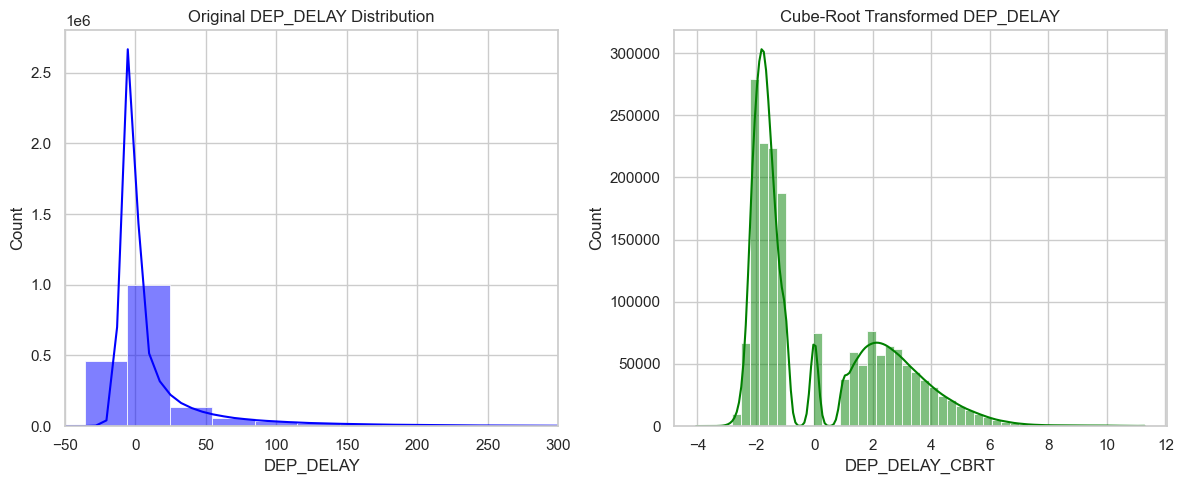

In [15]:
# Analyzing Skewness of DEP_DELAY
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['DEP_DELAY'], kde=True, color='blue', bins=50)
plt.title('Original DEP_DELAY Distribution')
plt.xlim(-50, 300) # Zooming in

# Applying Cube Root Transformation
df['DEP_DELAY_CBRT'] = np.cbrt(df['DEP_DELAY'])

plt.subplot(1, 2, 2)
sns.histplot(df['DEP_DELAY_CBRT'], kde=True, color='green', bins=50)
plt.title('Cube-Root Transformed DEP_DELAY')

plt.tight_layout()
plt.show()

## 3. Scaling and Normalization
We use **MinMaxScaler** to bound features between 0 and 1. Here, we apply it to `CRS_DEP_TIME` and `CRS_ARR_TIME`.

 Time strings successfully converted to continuous minutes!


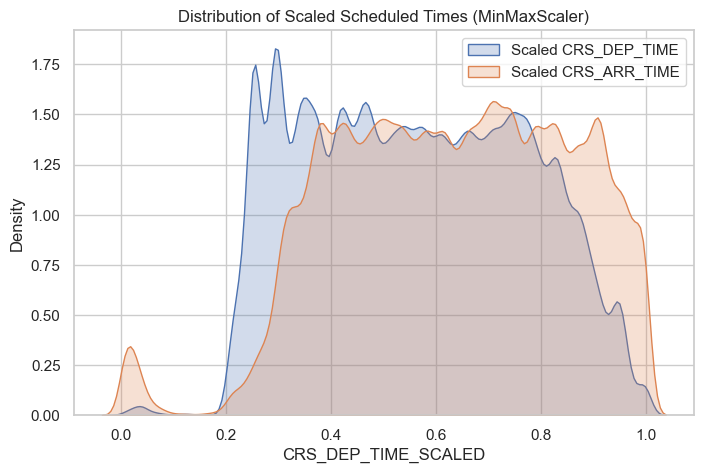

In [16]:

def time_to_minutes(time_str):
    if pd.isna(time_str):
        return np.nan
    try:
        hours, minutes = map(int, str(time_str).split(':'))
        return hours * 60 + minutes
    except:
        return np.nan

df['CRS_DEP_TIME'] = df['CRS_DEP_TIME'].apply(time_to_minutes)
df['CRS_ARR_TIME'] = df['CRS_ARR_TIME'].apply(time_to_minutes)

print(" Time strings successfully converted to continuous minutes!")

df['CRS_DEP_TIME'] = df['CRS_DEP_TIME'].fillna(df['CRS_DEP_TIME'].median())
df['CRS_ARR_TIME'] = df['CRS_ARR_TIME'].fillna(df['CRS_ARR_TIME'].median())

scaler = MinMaxScaler()
scaled_features = scaler.fit_transform(df[['CRS_DEP_TIME', 'CRS_ARR_TIME']])

df['CRS_DEP_TIME_SCALED'] = scaled_features[:, 0]
df['CRS_ARR_TIME_SCALED'] = scaled_features[:, 1]

plt.figure(figsize=(8, 5))
sns.kdeplot(df['CRS_DEP_TIME_SCALED'], label='Scaled CRS_DEP_TIME', fill=True)
sns.kdeplot(df['CRS_ARR_TIME_SCALED'], label='Scaled CRS_ARR_TIME', fill=True)
plt.title('Distribution of Scaled Scheduled Times (MinMaxScaler)')
plt.legend()
plt.show()

## 4. Encoding Categorical Variables
Machine Learning algorithms require numerical input. We encode the airline carrier (`OP_UNIQUE_CARRIER`) and the `ORIGIN` and `DEST` airports.
- Since there are many airports, **Label Encoding** is preferred over One-Hot Encoding to prevent massive dimensionality explosion.

In [17]:
le_carrier = LabelEncoder()
le_airport = LabelEncoder()

# Fit and transform Carriers
df['OP_UNIQUE_CARRIER_ENCODED'] = le_carrier.fit_transform(df['OP_UNIQUE_CARRIER'].astype(str))

# Create a combined vocabulary of all airports to ensure consistency across ORIGIN and DEST
all_airports = pd.concat([df['ORIGIN'], df['DEST']]).unique()
le_airport.fit(all_airports.astype(str))

# Transform Origin and Dest
df['ORIGIN_ENCODED'] = le_airport.transform(df['ORIGIN'].astype(str))
df['DEST_ENCODED'] = le_airport.transform(df['DEST'].astype(str))

print("Sample of Encoded Categorical Attributes:")
display(df[['OP_UNIQUE_CARRIER', 'OP_UNIQUE_CARRIER_ENCODED', 'ORIGIN', 'ORIGIN_ENCODED', 'DEST', 'DEST_ENCODED']].head(10))

Sample of Encoded Categorical Attributes:


,OP_UNIQUE_CARRIER,OP_UNIQUE_CARRIER_ENCODED,ORIGIN,ORIGIN_ENCODED,DEST,DEST_ENCODED
0,9E,0,ABE,0,ATL,20
1,9E,0,ABE,0,ATL,20
2,9E,0,AEX,11,ATL,20
3,9E,0,AEX,11,ATL,20
4,9E,0,AGS,12,ATL,20
5,9E,0,ALB,14,LGA,191
6,9E,0,ATL,20,ABE,0
7,9E,0,ATL,20,ABE,0
8,9E,0,ATL,20,AEX,11
9,9E,0,ATL,20,AEX,11


## 5. Saving the Engineered Dataset
We save the dataset with the new engineered features so it can be directly used for Dimensionality Reduction (PCA) in Week 7.

In [18]:
# Export to a new CSV file to preserve the pipeline stages
engineered_filename = 'flight_delay_engineered.csv'
df.to_csv(engineered_filename, index=False)
print(f"Successfully saved engineered dataset as: {engineered_filename}")
print(f"New Shape with engineered features: {df.shape}")

Successfully saved engineered dataset as: flight_delay_engineered.csv
New Shape with engineered features: (1747822, 33)
